<a href="https://colab.research.google.com/github/marco-siino/Agentic-ORAN-LLM/blob/main/rev1/Scenario_B_FlashCrowd_ALLM_vs_RuleBasedPPO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Scenario 2 (Flash Crowd)

# Installazione librerie

In [1]:
!pip install mistralai gymnasium stable-baselines3 shimmy pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 17.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [mistralai]


# Cell 1: Setup, Credentials, and A-LLM Brain (Scenario B)

In [6]:
import os
import time
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import requests

# ==============================================================================
# 1. CONFIGURATION
# ==============================================================================
API_KEY = 'mstrl_HH0jDdtNwQ2BLk5NIT6d3I5yMaKS9WWO_2WinhH'
MODEL_NAME = "ministral-14b-2512"

# ==============================================================================
# 2. MISTRAL LOGIC (A-LLM Agentic Brain)
# ==============================================================================
def get_llm_weights_per_cell(step, cell_id, price, traffic, safety_val):
    prompt_txt = f"""
    Context (Step {step}, Cell {cell_id}):
    - Energy Price: {price:.2f}x (Normal=1.0)
    - Traffic Load: {traffic:.0f}%
    - Safety Criticality: {safety_val:.0f}/100 (Normal=0, Emergency>80)

    Task: Output JSON weights (w_thr, w_eng, w_safe) summing to 1.0.
    Logic:
    1. Emergency (>80): w_safe must be 1.0.
    2. Flash Crowd (Traffic > 90%): w_thr >= 0.8 (Prioritize QoS to avoid SLA violation, override energy cost).
    3. High Energy Price (>4.0) & Normal Traffic: w_eng >= 0.8.
    4. Normal: Balance w_thr and w_eng.

    Output JSON ONLY: {{"w_thr": float, "w_eng": float, "w_safe": float}}
    """

    url = "https://api.mistral.ai/v1/chat/completions"
    headers = {
        "Content-Type": "application/json",
        "Authorization": f"Bearer {API_KEY}"
    }
    data = {
        "model": MODEL_NAME,
        "messages": [{"role": "user", "content": prompt_txt}],
        "temperature": 0.1
    }

    max_retries = 5
    for attempt in range(max_retries):
        try:
            response = requests.post(url, headers=headers, json=data)
            if response.status_code == 200:
                result = response.json()
                content = result["choices"][0]["message"]["content"]
                clean_json = content.replace("```json", "").replace("```", "").strip()
                d = json.loads(clean_json)
                return float(d.get('w_thr', 0.3)), float(d.get('w_eng', 0.3)), float(d.get('w_safe', 0.0)), prompt_txt, clean_json
            elif response.status_code == 429:
                wait_time = 2 ** attempt
                time.sleep(wait_time)
                continue
            else:
                break
        except Exception as e:
            time.sleep(2)

    return 0.7, 0.3, 0.0, prompt_txt, '{"error": "failed"}'

# ==============================================================================
# 3. RULE-BASED CONTROLLER (Reviewers' Baseline for Flash Crowd)
# ==============================================================================
def get_rule_based_weights(price, traffic, safety_val):
    if safety_val > 80.0:
        return 0.0, 0.0, 1.0
    # Rigid threshold: if traffic is high, prioritize throughput
    if traffic > 90.0:
        return 0.9, 0.1, 0.0
    if price > 4.0:
        return 0.1, 0.9, 0.0
    return 0.8, 0.2, 0.0

# Cell 2: Gym Environment & Single Run Simulation Engine

In [7]:
# ==============================================================================
# 4. O-RAN GYM ENVIRONMENT (Physics Engine)
# ==============================================================================
class ORAN3CellsEnv(gym.Env):
    def __init__(self):
        super(ORAN3CellsEnv, self).__init__()
        self.n_cells = 3
        self.action_space = spaces.Box(low=5.0, high=60.0, shape=(3,), dtype=np.float32)
        self.observation_space = spaces.Box(low=0, high=100, shape=(10,), dtype=np.float32)

        self.bandwidth = 100.0
        self.noise = 1.0
        self.max_pwr = 60.0
        self.min_pwr = 5.0

    def _calculate_metrics(self, power, traffic, price):
        snr = power / self.noise
        capacity = self.bandwidth * np.log2(1 + snr)
        throughput = capacity * (traffic / 100.0)
        consumption = power
        cost = power * price
        risk = ((self.max_pwr - power) / (self.max_pwr - self.min_pwr))**2
        sla_compliance = min(100.0, (throughput / 200.0) * 100.0)
        fairness = 1.0 - risk
        return throughput, consumption, cost, risk, sla_compliance, fairness

# ==============================================================================
# 5. TACTICAL OPTIMIZER (Conditional PPO Solver)
# ==============================================================================
def optimize_power(w_thr, w_eng, w_safe, price, traffic, env_instance):
    best_p = 5.0
    best_score = -np.inf

    for p in np.linspace(5, 60, 50):
        t, cons, c, r, sla, fair = env_instance._calculate_metrics(p, traffic, price)
        n_t = t / 800.0
        n_c = c / 600.0
        n_r = r

        score = (w_thr * n_t) - (w_eng * n_c) - (w_safe * n_r)
        if score > best_score:
            best_score = score
            best_p = p

    return best_p, best_score

# ==============================================================================
# 6. EXECUTION ENGINE (Single Run with Flash Crowd in Cell 2)
# ==============================================================================
def run_experiment_single(run_id):
    env = ORAN3CellsEnv()
    steps = 40
    history = []

    np.random.seed(42 + run_id)

    # 1. ENERGY PRICE: Shock and decay
    prices = np.ones(steps)
    prices[15] = 8.0
    for t in range(16, 30):
        prices[t] = 1.0 + 7.0 * np.exp(-0.3 * (t - 15))

    # 2. TRAFFIC: Flash Crowd injection in Cell 2 (Index 1) around steps 26-29
    traffic_c = []
    base_trend = np.linspace(40, 70, steps)
    for i in range(3):
        noise = np.random.normal(0, 5, steps)
        tr = np.clip(base_trend + noise, 10, 100)
        if i == 1:
            tr[26:30] = [92.0, 98.0, 100.0, 95.0]
        traffic_c.append(tr)

    safety_c2 = np.zeros(steps)

    print(f"🚀 STARTING SIMULATION RUN {run_id} (SCENARIO B: Flash Crowd)...")

    for t in range(steps):
        p = prices[t]
        row_data = {'Step': t, 'Price': p}

        print(f"\n{'='*80}")
        print(f"⏰ TIMESTEP {t} | Price Factor: {p:.2f}x")
        print(f"{'='*80}")

        for i in range(3):
            cid = i + 1
            tr = traffic_c[i][t]
            safe = safety_c2[t]

            flash_note = " [!!! FLASH CROWD CONGESTION !!!]" if (cid == 2 and tr > 90) else ""
            print(f"\n  📍 CELL {cid} [Load: {tr:.1f}%{flash_note}]")
            time.sleep(1.2)

            # --- 1. A-LLM (Agentic) ---
            wa_t, wa_e, wa_s, prompt_txt, json_resp = get_llm_weights_per_cell(t, cid, p, tr, safe)
            p_agentic, duf_agentic = optimize_power(wa_t, wa_e, wa_s, p, tr, env)

            print(f"    🔸 [A-LLM INTERACTION]")
            print(f"       OUTPUT JSON:     {json_resp}")
            print(f"       DECIDED WEIGHTS: W_Thr={wa_t:.2f}, W_Eng={wa_e:.2f}, W_Safe={wa_s:.2f}")
            print(f"       CHOSEN POWER:    {p_agentic:.1f} W (DUF: {duf_agentic:.4f})")

            # --- 2. RULE-BASED CONDITIONAL PPO (Baseline) ---
            wb_t, wb_e, wb_s = get_rule_based_weights(p, tr, safe)
            p_baseline, duf_baseline = optimize_power(wb_t, wb_e, wb_s, p, tr, env)

            print(f"    🔹 [RULE-BASED PPO]")
            print(f"       RULE WEIGHTS:    W_Thr={wb_t:.2f}, W_Eng={wb_e:.2f}, W_Safe={wb_s:.2f}")
            print(f"       CHOSEN POWER:    {p_baseline:.1f} W (DUF: {duf_baseline:.4f})")

            # --- 3. PHYSICAL METRICS ---
            ta, cons_a, ca, ra, slaa, faira = env._calculate_metrics(p_agentic, tr, p)
            tb, cons_b, cb, rb, slab, fairb = env._calculate_metrics(p_baseline, tr, p)

            prefix = f"C{cid}"
            row_data[f'{prefix}_Traffic'] = tr
            row_data[f'{prefix}_Safety'] = safe

            row_data[f'{prefix}_Cons_A'] = cons_a
            row_data[f'{prefix}_Cons_B'] = cons_b
            row_data[f'{prefix}_Cost_A'] = ca
            row_data[f'{prefix}_Cost_B'] = cb
            row_data[f'{prefix}_Thr_A'] = ta
            row_data[f'{prefix}_Thr_B'] = tb
            row_data[f'{prefix}_Risk_A'] = ra
            row_data[f'{prefix}_Risk_B'] = rb
            row_data[f'{prefix}_SLA_A'] = slaa
            row_data[f'{prefix}_SLA_B'] = slab

        history.append(row_data)

    df = pd.DataFrame(history)
    df.to_json(f"results_scenario2_run_{run_id}.json")
    print(f"\n✅ Simulation Run {run_id} Completed and Saved.")
    return df

# Cell 3: Automated Multi-Run Execution (5 Runs)

In [8]:
# ==============================================================================
# 7. AUTOMATED MULTI-RUN EXECUTION FOR STATISTICAL SIGNIFICANCE
# ==============================================================================
if __name__ == "__main__":
    NUM_RUNS = 5
    for r in range(NUM_RUNS):
        run_experiment_single(r)
    print("\n🎉 ALL SCENARIO 2 RUNS COMPLETED SUCCESSFULLY!")

Streaming output truncated to the last 5000 lines.
    "w_eng": 0.5,
    "w_safe": 0.0
}
       DECIDED WEIGHTS: W_Thr=0.50, W_Eng=0.50, W_Safe=0.00
       CHOSEN POWER:    36.4 W (DUF: 0.0816)
    🔹 [RULE-BASED PPO]
       RULE WEIGHTS:    W_Thr=0.80, W_Eng=0.20, W_Safe=0.00
       CHOSEN POWER:    60.0 W (DUF: 0.1833)

  📍 CELL 2 [Load: 33.0%]
    🔸 [A-LLM INTERACTION]
       OUTPUT JSON:     {
    "w_thr": 0.5,
    "w_eng": 0.5,
    "w_safe": 0.0
}
       DECIDED WEIGHTS: W_Thr=0.50, W_Eng=0.50, W_Safe=0.00
       CHOSEN POWER:    34.2 W (DUF: 0.0774)
    🔹 [RULE-BASED PPO]
       RULE WEIGHTS:    W_Thr=0.80, W_Eng=0.20, W_Safe=0.00
       CHOSEN POWER:    60.0 W (DUF: 0.1756)

  📍 CELL 3 [Load: 42.5%]
    🔸 [A-LLM INTERACTION]
       OUTPUT JSON:     {
    "w_thr": 0.5,
    "w_eng": 0.5,
    "w_safe": 0.0
}
       DECIDED WEIGHTS: W_Thr=0.50, W_Eng=0.50, W_Safe=0.00
       CHOSEN POWER:    45.4 W (DUF: 0.1091)
    🔹 [RULE-BASED PPO]
       RULE WEIGHTS:    W_Thr=0.80, W_Eng=0.20, W

# Cell 4: IEEE Plotting & Statistical LaTeX Table Generator (English)

📊 Loading data from results_scenario2_run_0.json for plotting...


<>:150: SyntaxWarning: invalid escape sequence '\p'
<>:150: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_1285/3657523585.py:150: SyntaxWarning: invalid escape sequence '\p'
  else: txt = f"{mu:.1f} $\pm$ {sigma:.1f}"


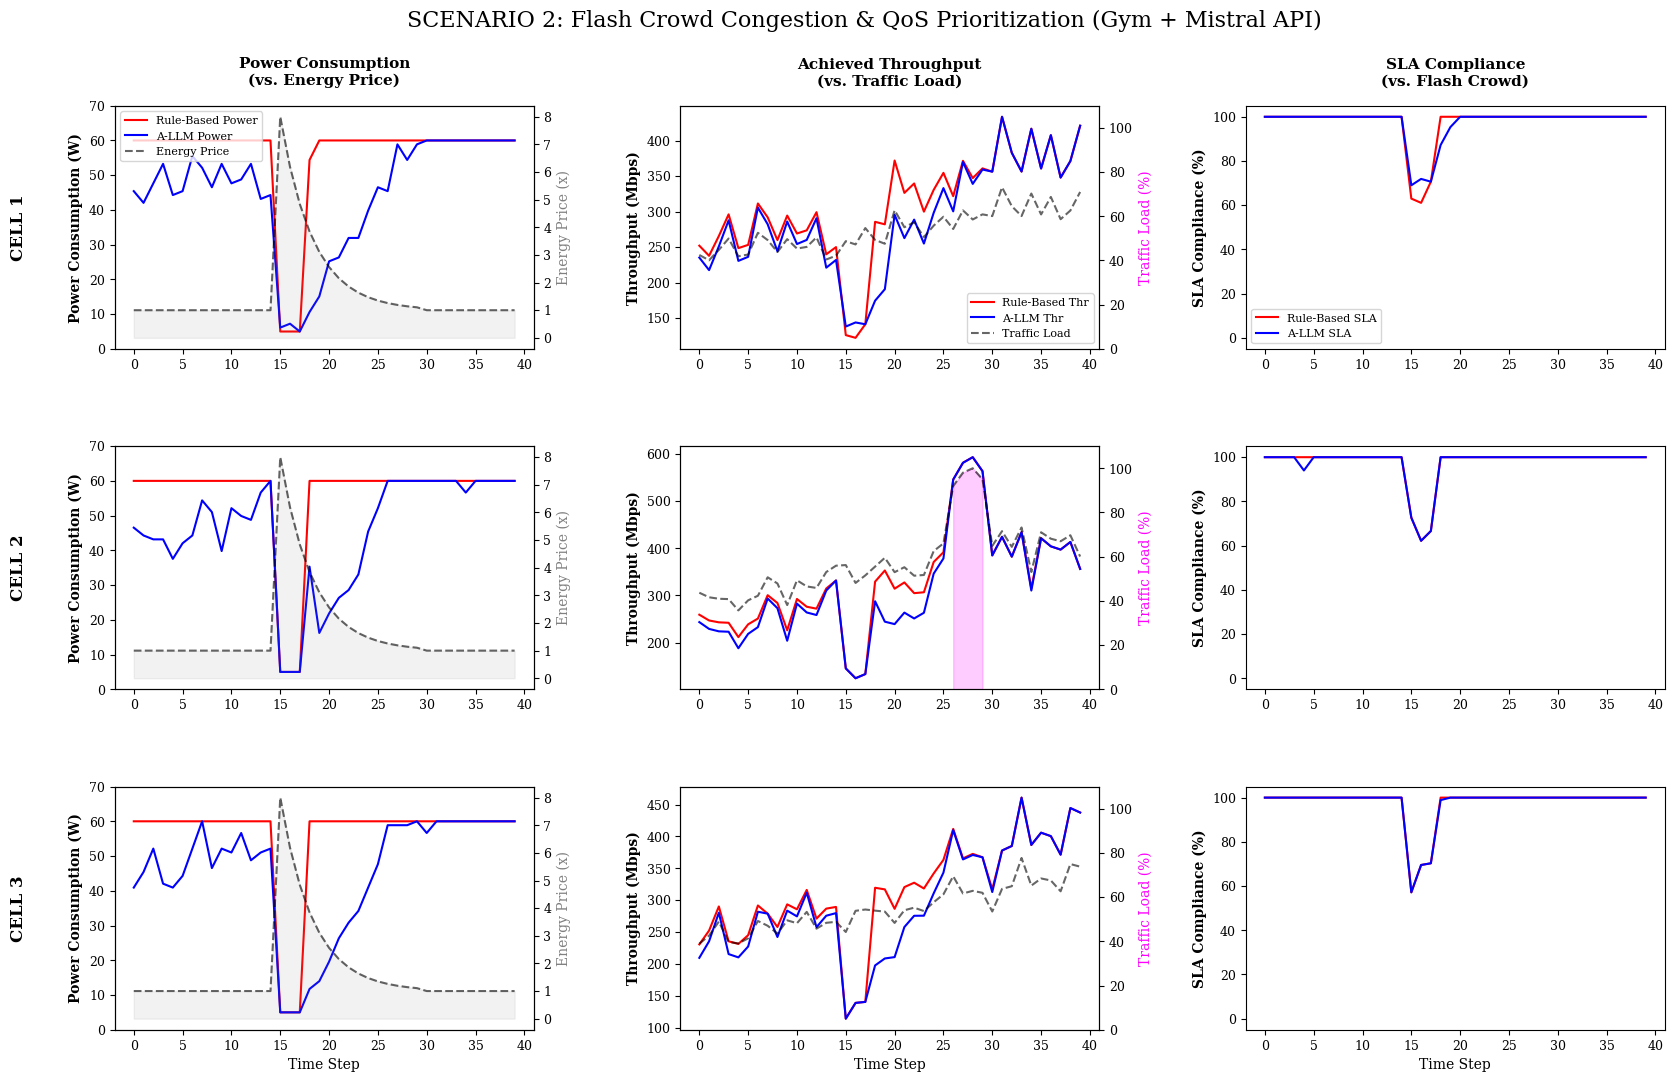

✅ Plot saved as 'scenario2_flash_crowd_results.pdf'.

📊 Processing 5 runs for Scenario 2 LaTeX table...


% === COPY THIS TABLE INTO YOUR LATEX ===
\begin{table*}[t]
\centering
\caption{Scenario 2 Analysis: Comparative Results during Flash Crowd Congestion (Step 26-29) across 3 Cells}
\label{tab:detailed_results_scenario2}
\resizebox{\textwidth}{!}{%
\scriptsize
\begin{tabular}{clccccc}
\toprule
\textbf{Event} & \textbf{Method} & \textbf{Throughput} & \textbf{Energy Cost} & \textbf{Power} & \textbf{SLA Viol.} & \textbf{Safety Risk} \\
 & & (Mbps) & (Units) & (Watts) & (Ratio 0-1) & (Prob.) \\
\midrule
\multicolumn{7}{l}{\textbf{Flash Crowd Congestion in Cell 2 (Step 26-29)}} \\
\midrule
\multirow{3}{*}{Cell 1} & Rule-Based PPO & \textbf{363.9 $\pm$ 9.2} & 70 & 60.0 & \textbf{0.10} & \textbf{0.00} \\
 & \textbf{A-LLM (Ours)} & 354.7 $\pm$ 9.2 & \textbf{63} & \textbf{54.2 $\pm$ 2.6} & \textbf{0.20} & 0.02 \\
 & \textit{Diff.} & \textit{-2.5\%} & \textit{\textbf{-10.0\%}} & \textit{\textb

In [9]:
# ==============================================================================
# 8. IEEE PLOTTING FUNCTION (Scenario 2 - English Labels)
# ==============================================================================
def generate_plots(run_id_to_plot=0):
    filename = f"results_scenario2_run_{run_id_to_plot}.json"
    try:
        df = pd.read_json(filename)
        print(f"📊 Loading data from {filename} for plotting...")
    except:
        print(f"❌ Error: Could not find {filename}. Run simulations first.")
        return

    plt.rcParams.update({
        'font.size': 10, 'font.family': 'serif',
        'axes.labelsize': 10, 'axes.titlesize': 11,
        'xtick.labelsize': 9, 'ytick.labelsize': 9,
        'legend.fontsize': 9, 'lines.linewidth': 1.5
    })

    fig, axes = plt.subplots(3, 3, figsize=(20, 12))
    plt.subplots_adjust(hspace=0.4, wspace=0.35)

    cols = ["Power Consumption\n(vs. Energy Price)", "Achieved Throughput\n(vs. Traffic Load)", "SLA Compliance\n(vs. Flash Crowd)"]
    for ax, t in zip(axes[0], cols): ax.set_title(t, fontweight='bold', pad=15)

    for i in range(3):
        cid = i + 1
        pid = f"C{cid}"

        axes[i, 0].text(-0.25, 0.5, f"CELL {cid}", transform=axes[i, 0].transAxes,
                        rotation=90, fontweight='bold', fontsize=12, va='center')

        # --- PLOT 1: Power vs Price ---
        ax = axes[i, 0]
        l1, = ax.plot(df['Step'], df[f'{pid}_Cons_B'], 'r-', label='Rule-Based PPO')
        l2, = ax.plot(df['Step'], df[f'{pid}_Cons_A'], 'b-', label='A-LLM (Agentic)')
        ax.set_ylim(0, 70)
        ax.set_ylabel("Power Consumption (W)", fontweight='bold')
        if i==2: ax.set_xlabel("Time Step")

        ax2 = ax.twinx()
        l3, = ax2.plot(df['Step'], df['Price'], 'k--', alpha=0.6, label='Energy Price')
        ax2.fill_between(df['Step'], 0, df['Price'], color='gray', alpha=0.1)
        ax2.set_ylabel("Energy Price (x)", color='gray')

        if i==0: ax.legend([l1, l2, l3], ['Rule-Based Power', 'A-LLM Power', 'Energy Price'], loc='upper left', fontsize=8)

        # --- PLOT 2: Throughput vs Traffic (Flash Crowd Highlighted) ---
        ax = axes[i, 1]
        l1, = ax.plot(df['Step'], df[f'{pid}_Thr_B'], 'r-')
        l2, = ax.plot(df['Step'], df[f'{pid}_Thr_A'], 'b-')
        ax.set_ylabel("Throughput (Mbps)", fontweight='bold')
        if i==2: ax.set_xlabel("Time Step")

        ax2 = ax.twinx()
        l3, = ax2.plot(df['Step'], df[f'{pid}_Traffic'], 'k--', alpha=0.6)
        if cid == 2:
            ax2.fill_between(df['Step'], 0, df[f'{pid}_Traffic'], where=(df['Step']>=26) & (df['Step']<=29), color='magenta', alpha=0.2)
        ax2.set_ylabel("Traffic Load (%)", color='magenta')
        ax2.set_ylim(0, 110)

        if i==0: ax.legend([l1, l2, l3], ['Rule-Based Thr', 'A-LLM Thr', 'Traffic Load'], loc='lower right', fontsize=8)

        # --- PLOT 3: SLA Compliance ---
        ax = axes[i, 2]
        l1, = ax.plot(df['Step'], df[f'{pid}_SLA_B'], 'r-')
        l2, = ax.plot(df['Step'], df[f'{pid}_SLA_A'], 'b-')
        ax.set_ylim(-5, 105)
        ax.set_ylabel("SLA Compliance (%)", fontweight='bold')
        if i==2: ax.set_xlabel("Time Step")

        if i==0: ax.legend([l1, l2], ['Rule-Based SLA', 'A-LLM SLA'], loc='lower left', fontsize=8)

    plt.suptitle("SCENARIO 2: Flash Crowd Congestion & QoS Prioritization (Gym + Mistral API)", fontsize=16, y=0.96)
    plt.savefig("scenario2_flash_crowd_results.pdf", bbox_inches='tight', dpi=300)
    plt.show()
    print("✅ Plot saved as 'scenario2_flash_crowd_results.pdf'.")

# ==============================================================================
# 9. LATEX TABLE GENERATOR (Mean ± Std over 5 Runs - English)
# ==============================================================================
def generate_paper_table_structural_sep(num_runs_to_analyze=5):
    RECALC_SLA_THR = 330.0

    results = {
        'Crowd': {1: {}, 2: {}, 3: {}, 'Global': {}}
    }

    for c in [1, 2, 3, 'Global']:
        for m in ['Base', 'Agent']:
            results['Crowd'][c][m] = {'thr':[], 'cost':[], 'pwr':[], 'sla':[], 'risk':[]}

    print(f"\n📊 Processing {num_runs_to_analyze} runs for Scenario 2 LaTeX table...")

    for i in range(num_runs_to_analyze):
        fname = f"results_scenario2_run_{i}.json"
        try:
            df = pd.read_json(fname)
        except:
            print(f"⚠️ {fname} not found. Skipping...")
            continue

        df_Crowd = df[(df['Step'] >= 26) & (df['Step'] <= 29)]

        for cid in [1, 2, 3]:
            pre = f"C{cid}"
            traf_col = f'{pre}_Traffic'
            for m_type, suffix in [('Base', '_B'), ('Agent', '_A')]:
                thr_col = f'{pre}_Thr{suffix}'

                results['Crowd'][cid][m_type]['thr'].append(df_Crowd[thr_col].mean())
                results['Crowd'][cid][m_type]['cost'].append(df_Crowd[f'{pre}_Cost{suffix}'].mean())
                results['Crowd'][cid][m_type]['pwr'].append(df_Crowd[f'{pre}_Cons{suffix}'].mean())
                results['Crowd'][cid][m_type]['risk'].append(df_Crowd[f'{pre}_Risk{suffix}'].mean())

                sla_series = ((df_Crowd[thr_col] < RECALC_SLA_THR) & (df_Crowd[traf_col] > 10.0)).astype(float)
                results['Crowd'][cid][m_type]['sla'].append(sla_series.mean())

        for m_type, suffix in [('Base', '_B'), ('Agent', '_A')]:
            mean_thr = df_Crowd[[f'C{k}_Thr{suffix}' for k in [1,2,3]]].mean().mean()
            mean_cost = df_Crowd[[f'C{k}_Cost{suffix}' for k in [1,2,3]]].mean().mean()
            mean_pwr = df_Crowd[[f'C{k}_Cons{suffix}' for k in [1,2,3]]].mean().mean()
            mean_risk = df_Crowd[[f'C{k}_Risk{suffix}' for k in [1,2,3]]].mean().mean()

            sla_vals = []
            for k in [1, 2, 3]:
                s = ((df_Crowd[f'C{k}_Thr{suffix}'] < RECALC_SLA_THR) & (df_Crowd[f'C{k}_Traffic'] > 10.0)).astype(float)
                sla_vals.append(s.mean())
            mean_sla = np.mean(sla_vals)

            results['Crowd']['Global'][m_type]['thr'].append(mean_thr)
            results['Crowd']['Global'][m_type]['cost'].append(mean_cost)
            results['Crowd']['Global'][m_type]['pwr'].append(mean_pwr)
            results['Crowd']['Global'][m_type]['sla'].append(mean_sla)
            results['Crowd']['Global'][m_type]['risk'].append(mean_risk)

    def fmt(vals, is_pct=False, is_cost=False, is_decimal=False, bold=False):
        if not vals or np.isnan(np.mean(vals)): return "-"
        mu = np.mean(vals)
        sigma = np.std(vals)
        txt = ""
        if is_decimal:
            txt = f"{mu:.2f}"
        elif is_pct:
            txt = f"{mu*100:.1f}"
        elif is_cost:
            txt = f"{mu:.0f}"
        else:
            if sigma < 0.1: txt = f"{mu:.1f}"
            else: txt = f"{mu:.1f} $\pm$ {sigma:.1f}"

        if bold: return f"\\textbf{{{txt}}}"
        return txt

    def get_diff_str(base_vals, agent_vals, metric_type='lower_better', is_absolute_delta=False):
        if not base_vals or not agent_vals: return "-"
        b = np.mean(base_vals)
        a = np.mean(agent_vals)
        if b == 0 and not is_absolute_delta: return "-"

        if is_absolute_delta:
            delta = a - b
            txt = f"{delta:+.2f}"
            is_improvement = (metric_type == 'lower_better' and delta < -0.001) or (metric_type == 'higher_better' and delta > 0.001)
        else:
            delta = ((a - b) / b) * 100
            txt = f"{delta:+.1f}\\%"
            is_improvement = (metric_type == 'lower_better' and delta < -0.1) or (metric_type == 'higher_better' and delta > 0.1)

        if is_improvement: return f"\\textbf{{{txt}}}"
        return txt

    def check_winner(base_vals, agent_vals, metric_type):
        if not base_vals or not agent_vals: return False, False
        b = np.mean(base_vals)
        a = np.mean(agent_vals)
        if metric_type == 'lower_better': return (a < b), (b < a)
        else: return (a > b), (b > a)

    print("\n\n% === COPY THIS TABLE INTO YOUR LATEX ===")
    print(r"\begin{table*}[t]")
    print(r"\centering")
    print(r"\caption{Scenario 2 Analysis: Comparative Results during Flash Crowd Congestion (Step 26-29) across 3 Cells}")
    print(r"\label{tab:detailed_results_scenario2}")
    print(r"\resizebox{\textwidth}{!}{%")
    print(r"\scriptsize")
    print(r"\begin{tabular}{clccccc}")
    print(r"\toprule")
    print(r"\textbf{Event} & \textbf{Method} & \textbf{Throughput} & \textbf{Energy Cost} & \textbf{Power} & \textbf{SLA Viol.} & \textbf{Safety Risk} \\")
    print(r" & & (Mbps) & (Units) & (Watts) & (Ratio 0-1) & (Prob.) \\")
    print(r"\midrule")
    print(r"\multicolumn{7}{l}{\textbf{Flash Crowd Congestion in Cell 2 (Step 26-29)}} \\")
    print(r"\midrule")

    for k in [1, 2, 3, 'Global']:
        b = results['Crowd'][k]['Base']
        a = results['Crowd'][k]['Agent']

        if k != 1: print(r"\midrule")

        if k == 'Global':
            row_label = r"\textbf{Network Avg}"
        else:
            row_label = f"Cell {k}"
            if k == 2: row_label += r" \textit{(Congested Cell)}"

        w_thr_a, w_thr_b = check_winner(b['thr'], a['thr'], 'higher_better')
        w_cost_a, w_cost_b = check_winner(b['cost'], a['cost'], 'lower_better')
        w_pwr_a, w_pwr_b = check_winner(b['pwr'], a['pwr'], 'lower_better')
        w_sla_a, w_sla_b = check_winner(b['sla'], a['sla'], 'lower_better')
        w_risk_a, w_risk_b = check_winner(b['risk'], a['risk'], 'lower_better')

        print(f"\\multirow{{3}}{{*}}{{{row_label}}} & Rule-Based PPO & "
              f"{fmt(b['thr'], bold=w_thr_b)} & {fmt(b['cost'], is_cost=True, bold=w_cost_b)} & "
              f"{fmt(b['pwr'], bold=w_pwr_b)} & {fmt(b['sla'], is_decimal=True, bold=w_sla_b)} & "
              f"{fmt(b['risk'], is_decimal=True, bold=w_risk_b)} \\\\")

        print(f" & \\textbf{{A-LLM (Ours)}} & "
              f"{fmt(a['thr'], bold=w_thr_a)} & {fmt(a['cost'], is_cost=True, bold=w_cost_a)} & "
              f"{fmt(a['pwr'], bold=w_pwr_a)} & {fmt(a['sla'], is_decimal=True, bold=w_sla_b)} & "
              f"{fmt(a['risk'], is_decimal=True, bold=w_risk_a)} \\\\")

        d_thr = get_diff_str(b['thr'], a['thr'], 'higher_better')
        d_cost = get_diff_str(b['cost'], a['cost'], 'lower_better')
        d_pwr = get_diff_str(b['pwr'], a['pwr'], 'lower_better')
        d_sla = get_diff_str(b['sla'], a['sla'], 'lower_better', is_absolute_delta=True)
        d_risk = get_diff_str(b['risk'], a['risk'], 'lower_better', is_absolute_delta=True)

        print(f" & \\textit{{Diff.}} & "
              f"\\textit{{{d_thr}}} & \\textit{{{d_cost}}} & \\textit{{{d_pwr}}} & "
              f"\\textit{{{d_sla}}} & {d_risk} \\\\")

    print(r"\bottomrule")
    print(r"\end{tabular}%")
    print(r"}")
    print(r"\vspace{0.1cm}")
    print(r"\\ \footnotesize{\textit{Note: Diff. row shows percentage change for Thr/Cost/Power, and absolute difference ($\Delta$) for SLA/Risk. Bold indicates the superior metric. Values represent the mean $\pm$ standard deviation computed over 5 independent simulation runs.}}")
    print(r"\end{table*}")

if __name__ == "__main__":
    generate_plots(run_id_to_plot=0)
    generate_paper_table_structural_sep(5)